# Proyecto Machine Learning: Predicción de Éxito Musical en Spotify

-Emmanuel Chavero

-Benjamin Figueroa

-Daniel Vidal
## Fase 1: Comprensión del Negocio

**Contexto:**
La industria musical es altamente competitiva. Plataformas como Spotify utilizan complejos algoritmos para recomendar música. Entender qué hace que una canción sea popular puede ser la diferencia entre un éxito mundial y un fracaso comercial.

**Objetivo Comercial:**
Analizar las características acústicas (bailabilidad, energía, tempo, etc.) y metadatos de un amplio catálogo de canciones para identificar los factores que impulsan la popularidad de una pista. Esto servirá para ayudar a productores musicales, artistas y sellos discográficos a tomar decisiones informadas sobre composición musical y estrategias de marketing.

**Objetivos de Machine Learning:**
*   Explorar y perfilar un conjunto de datos de 114,000 canciones de Spotify.
*   Preparar los datos para el modelado (limpieza y transformación).
*   **Meta Principal:** Desarrollar un modelo predictivo capaz de estimar el nivel de popularidad (`popularity`) de una canción basándose en sus características de audio (`danceability`, `energy`, `acousticness`, etc.).

**Traducción Analítica:**
*   **Tipo de problema:** Regresión — la variable objetivo `popularity` es continua (0–100). Como alternativa, la Fase 5 evalúa reformularlo como clasificación por rangos (baja/media/alta).
*   **Variable objetivo (Target):** `popularity`.

**Métrica de Impacto (costo del error para el negocio):**
*   **Subestimar un éxito** (predecir baja popularidad a un potencial hit): oportunidad de inversión y promoción perdida.
*   **Sobreestimar un fracaso** (predecir alta popularidad a una canción floja): inversión de marketing desperdiciada.
*   Ambos errores importan: se reporta MAE (error típico), RMSE (castiga errores graves) y R² (capacidad explicativa). En la variante de clasificación, el falso negativo —dejar escapar un hit— es el error más caro, por lo que el Recall de la clase "Alta" sería la métrica a proteger.

**Criterios de Éxito:**
Obtener un modelo de Machine Learning que logre predecir la popularidad con un margen de error aceptable para el negocio (R² superior al umbral de 0.30 que la guía considera mínimo para decisiones), permitiendo identificar potenciales "hits" antes de su lanzamiento.

## Fase 2: Comprensión de los Datos

En esta fase importaremos las librerías necesarias, cargaremos el conjunto de datos y realizaremos un Análisis Exploratorio de Datos (EDA) inicial para conocer la forma, el tipo de variables, la presencia de valores nulos y la distribución estadística de nuestro *dataset*.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Spotify_Tracks_Dataset.csv")

df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [2]:
print("--- DIMENSIONES DEL DATASET ---")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}\n")

print("--- INFORMACIÓN GENERAL Y TIPOS DE DATOS ---")
df.info()

print("\n--- VALORES NULOS ---")
print(df.isnull().sum())

--- DIMENSIONES DEL DATASET ---
Filas: 114000
Columnas: 21

--- INFORMACIÓN GENERAL Y TIPOS DE DATOS ---
<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      1140

**Conclusiones de la Inspección Inicial:**
1.  **Estructura:** El dataset consta de 114,000 registros y 21 columnas.
2.  **Datos Innecesarios:** Se observa una columna `Unnamed: 0` que actúa como un índice redundante y no aporta valor analítico.
3.  **Calidad de Datos:** El dataset está notablemente limpio. Solo se detecta 1 valor nulo en las columnas de texto (`artists`, `album_name`, `track_name`).
4.  **Tipos de Datos:** Tenemos una mezcla útil de variables categóricas (género, nombre del artista) y variables numéricas continuas/discretas (características de audio como volumen, tempo, energía).

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
count,114000.000000,114000,113999,113999,113999,114000.000000,1.140000e+05,114000,114000.000000,114000.000000,...,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000
unique,NaN,89741,31437,46589,73608,NaN,NaN,2,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,114
top,NaN,6S3JlDAGk3uu3NtZbPnuhS,The Beatles,Alternative Christmas 2022,Run Rudolph Run,NaN,NaN,False,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,acoustic
freq,NaN,9,279,195,151,NaN,NaN,104253,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1000
mean,56999.500000,NaN,NaN,NaN,NaN,33.238535,2.280292e+05,NaN,0.566800,0.641383,...,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035,NaN
std,32909.109681,NaN,NaN,NaN,NaN,22.305078,1.072977e+05,NaN,0.173542,0.251529,...,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621,NaN
min,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000e+00,NaN,0.000000,0.000000,...,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
25%,28499.750000,NaN,NaN,NaN,NaN,17.000000,1.740660e+05,NaN,0.456000,0.472000,...,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000,NaN
50%,56999.500000,NaN,NaN,NaN,NaN,35.000000,2.129060e+05,NaN,0.580000,0.685000,...,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000,NaN
75%,85499.250000,NaN,NaN,NaN,NaN,50.000000,2.615060e+05,NaN,0.695000,0.854000,...,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000,NaN


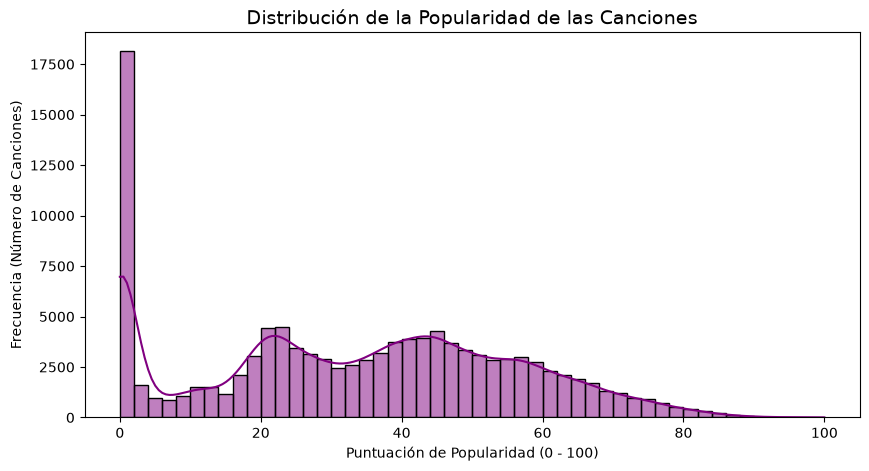

In [3]:
display(df.describe(include='all'))


plt.figure(figsize=(10, 5))
sns.histplot(df['popularity'], bins=50, kde=True, color='purple')
plt.title('Distribución de la Popularidad de las Canciones', fontsize=14)
plt.xlabel('Puntuación de Popularidad (0 - 100)')
plt.ylabel('Frecuencia (Número de Canciones)')
plt.show()

### Interpretación de la Distribución de Popularidad
*   **Comportamiento Anómalo en el Cero:** El hallazgo más crítico es el enorme pico de canciones con popularidad exactamente igual a 0. Esto sugiere que una gran parte del catálogo son canciones no escuchadas, ruido, o pistas que la plataforma acaba de subir y aún no tienen métricas.
*   **Distribución No Normal:** Descartando los ceros, la distribución tiene múltiples picos (bimodal/multimodal) concentrándose entre los valores 20 y 50. Muy pocas canciones logran superar el umbral de 80.
*   **Implicación para el Modelo:** Predecir exactamente el número de popularidad será difícil mediante regresión lineal simple debido a esta distribución.

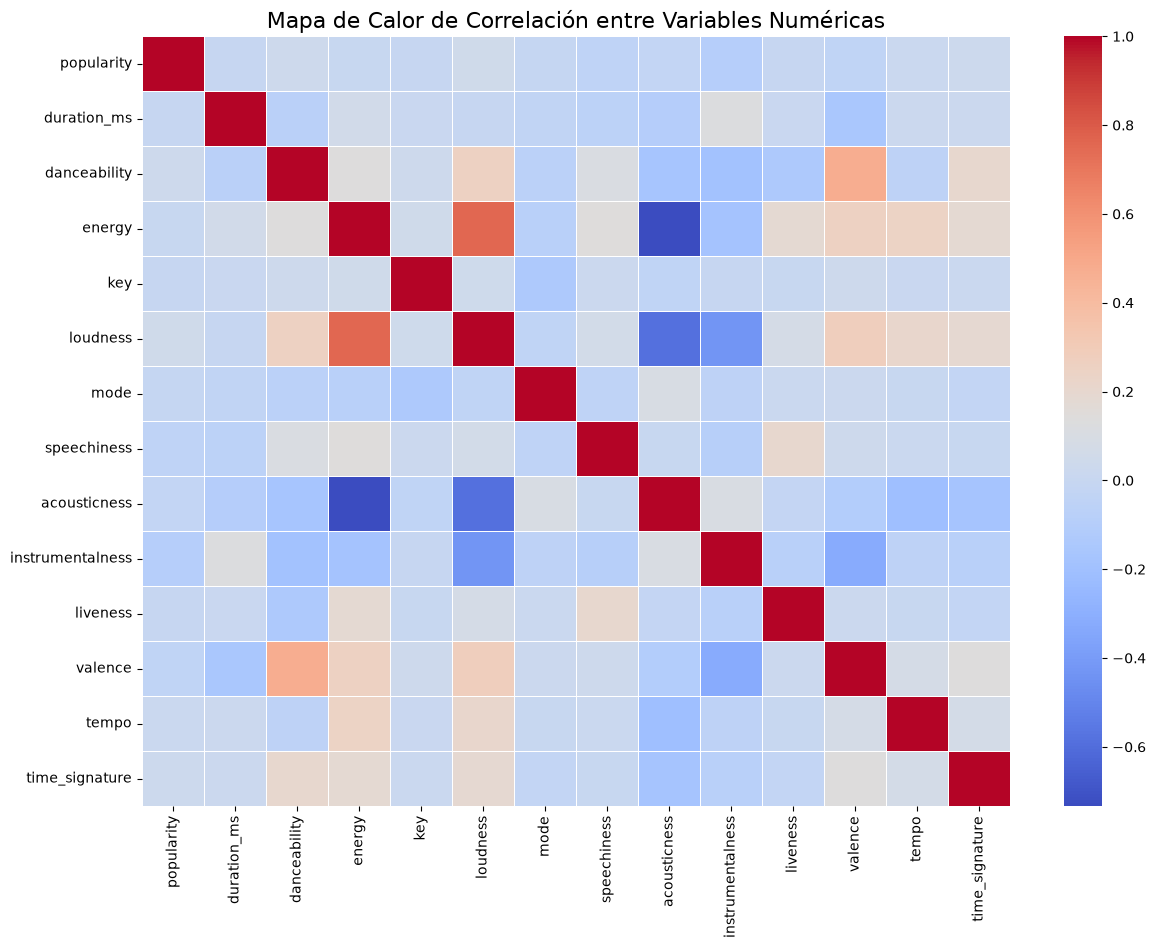

In [4]:
columnas_numericas = df.select_dtypes(include=['float64', 'int64']).columns
if 'Unnamed: 0' in columnas_numericas:
    columnas_numericas = columnas_numericas.drop('Unnamed: 0')

correlacion = df[columnas_numericas].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(correlacion, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Mapa de Calor de Correlación entre Variables Numéricas', fontsize=16)
plt.show()

### Interpretación del Mapa de Calor (Correlación)
*   **Correlaciones Fuertes Lógicas:** Existe una alta correlación positiva entre `energy` (energía) y `loudness` (volumen). A su vez, ambas tienen una fuerte correlación negativa con `acousticness` (acústica). Esto tiene sentido musical: las canciones acústicas no suelen ser ruidosas ni de alta energía.
*   **Relación con la Popularidad:** Sorprendentemente, ninguna de las variables numéricas acústicas presenta una correlación lineal fuerte con nuestra variable objetivo (`popularity`).
*   **Implicación para el Modelo:** Dado que no hay relaciones lineales fuertes y directas con la popularidad, los modelos simples (como Regresión Lineal) probablemente tendrán un mal rendimiento. Necesitaremos modelos más complejos que detecten patrones no lineales.

### Análisis Bivariado: Exploración de Patrones No Lineales
Para visualizar la relación directa de nuestras variables acústicas contra la variable objetivo (`popularity`), utilizamos gráficos de dispersión.

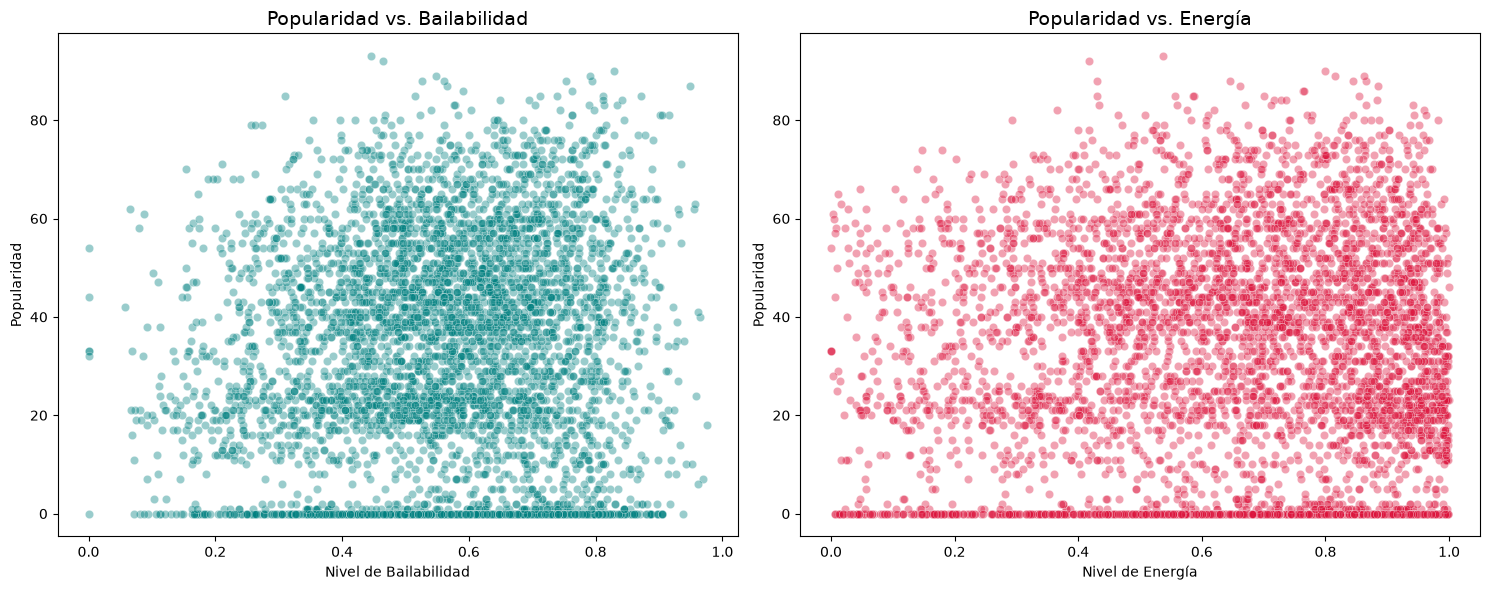

In [5]:
muestra_df = df.sample(n=5000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(ax=axes[0], data=muestra_df, x='danceability', y='popularity', alpha=0.4, color='teal')
axes[0].set_title('Popularidad vs. Bailabilidad', fontsize=14)
axes[0].set_xlabel('Nivel de Bailabilidad')
axes[0].set_ylabel('Popularidad')

sns.scatterplot(ax=axes[1], data=muestra_df, x='energy', y='popularity', alpha=0.4, color='crimson')
axes[1].set_title('Popularidad vs. Energía', fontsize=14)
axes[1].set_xlabel('Nivel de Energía')
axes[1].set_ylabel('Popularidad')

plt.tight_layout()
plt.show()

**Interpretación de los Gráficos de Dispersión:**
*   **Falta de Linealidad:** Las nubes de puntos confirman el hallazgo del mapa de calor; no existe una línea recta que indique "a mayor bailabilidad, mayor popularidad". Los datos están muy dispersos.
*   **El Muro de los Ceros:** Se observa una fuerte línea horizontal de puntos en el nivel de popularidad 0, abarcando todos los rangos posibles de energía y bailabilidad. Esto refuerza la teoría de que la popularidad nula no se debe a la acústica de la canción, sino a su falta de exposición, antigüedad o métricas faltantes en la plataforma.
*   **Decisión Técnica:** Queda descartado el uso de algoritmos básicos como la Regresión Lineal Simple. Necesitaremos modelos basados en árboles (Decision Trees, Random Forest) o redes neuronales que puedan capturar interacciones complejas.

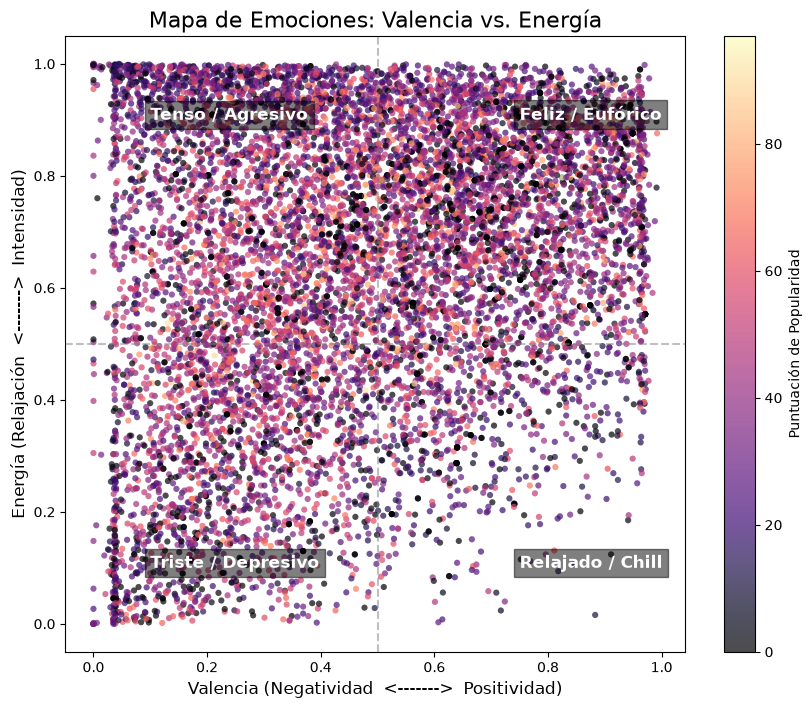

In [6]:
muestra_emociones = df.sample(n=10000, random_state=42)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(x=muestra_emociones['valence'],
                      y=muestra_emociones['energy'],
                      c=muestra_emociones['popularity'],
                      cmap='magma', alpha=0.7, edgecolors='none', s=20)

plt.colorbar(scatter, label='Puntuación de Popularidad')

plt.axvline(x=0.5, color='gray', linestyle='--', alpha=0.5)
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)

plt.title('Mapa de Emociones: Valencia vs. Energía', fontsize=16)
plt.xlabel('Valencia (Negatividad  <------->  Positividad)', fontsize=12)
plt.ylabel('Energía (Relajación  <------->  Intensidad)', fontsize=12)

plt.text(0.1, 0.9, 'Tenso / Agresivo', fontsize=12, color='white', weight='bold', bbox=dict(facecolor='black', alpha=0.5))
plt.text(0.75, 0.9, 'Feliz / Eufórico', fontsize=12, color='white', weight='bold', bbox=dict(facecolor='black', alpha=0.5))
plt.text(0.1, 0.1, 'Triste / Depresivo', fontsize=12, color='white', weight='bold', bbox=dict(facecolor='black', alpha=0.5))
plt.text(0.75, 0.1, 'Relajado / Chill', fontsize=12, color='white', weight='bold', bbox=dict(facecolor='black', alpha=0.5))

plt.show()

**Implicaciones del Mapa de Emociones para el Modelo Predictivo**

*   **Interacción de Características (Feature Interaction):** El gráfico demuestra que el algoritmo no podrá predecir el éxito evaluando estas variables de forma aislada. Una canción tensa (baja valencia) puede ser un éxito masivo, pero *solo si* viene acompañada de alta energía. Necesitaremos entrenar modelos capaces de entender combinaciones complejas y espacios multidimensionales.
*   **Descarte de Modelos Lineales:** La dispersión de la nube de puntos confirma la ausencia de una correlación lineal simple. Un algoritmo de Regresión Lineal básica tendrá un rendimiento deficiente porque intentará trazar una línea recta donde claramente existen agrupaciones o "cuadrantes" de comportamiento.

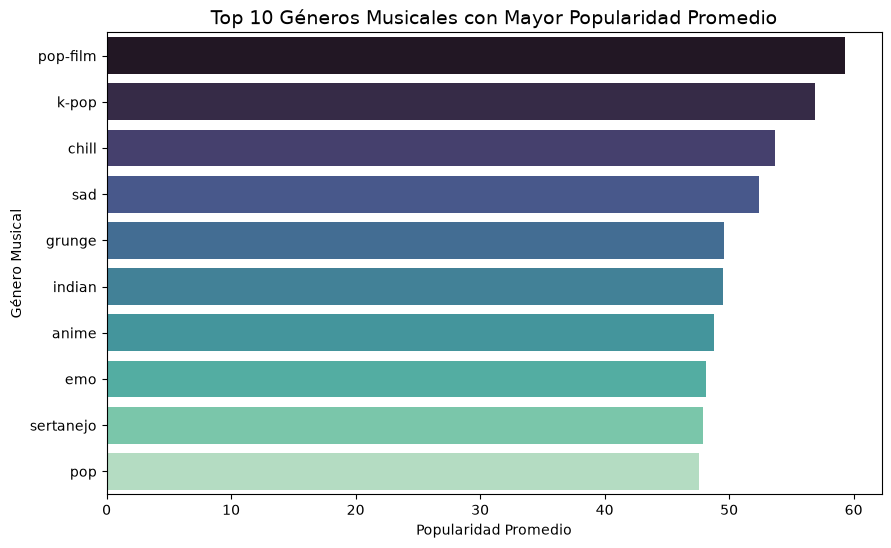

In [7]:
top_generos = df.groupby('track_genre')['popularity'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_generos.values, y=top_generos.index, hue=top_generos.index, legend=False, palette='mako')
plt.title('Top 10 Géneros Musicales con Mayor Popularidad Promedio', fontsize=14)
plt.xlabel('Popularidad Promedio')
plt.ylabel('Género Musical')
plt.show()

### Interpretación de Variables Categóricas (Top Géneros)
*   **Impacto del Género:** A diferencia de las variables numéricas, el género musical (`track_genre`) sí parece tener un impacto drástico en la popularidad.
*   Géneros de nicho cinematográfico (`pop-film`) o fenómenos globales (`k-pop`) lideran la plataforma con promedios cercanos a 60, mientras que la media general del dataset es de solo 33.2.
*   **Implicación para la Fase 3:** Será fundamental transformar correctamente esta columna de texto a formato numérico (One-Hot Encoding o Target Encoding) para que el modelo de Machine Learning pueda aprovechar esta valiosa información.

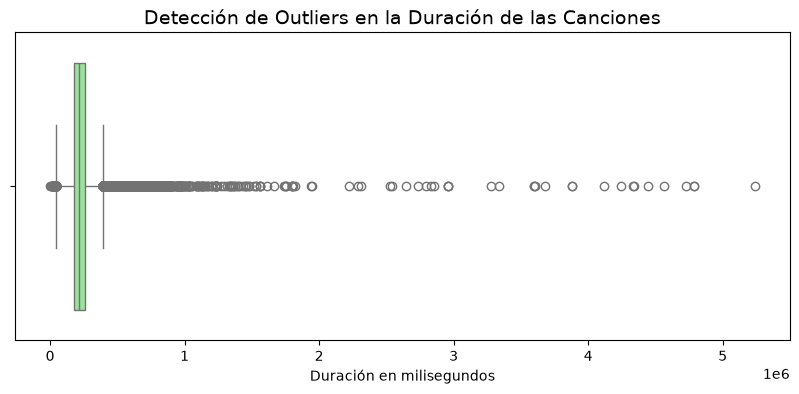

In [8]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['duration_ms'], color='lightgreen')
plt.title('Detección de Outliers en la Duración de las Canciones', fontsize=14)
plt.xlabel('Duración en milisegundos')
plt.show()

### Interpretación de Outliers (Duración)
*   **Valores Extremos:** El diagrama de caja revela una cantidad masiva de valores atípicos (outliers) en el extremo superior.
*   Mientras que el promedio (mean) es de aproximadamente 228,000 milisegundos (unos 3.8 minutos), existen pistas que superan los 5 millones de milisegundos (más de 80 minutos). Esto podría corresponder a ruidos blancos, podcasts mal clasificados o sesiones de meditación.
*   **Implicación para la Fase 3:** Estos valores extremos pueden sesgar y confundir al algoritmo predictivo. En la etapa de Preparación de Datos, deberemos decidir si eliminar las canciones que superen cierto umbral de duración (por ejemplo, más de 10 minutos) para que el modelo se enfoque en música comercial estándar.

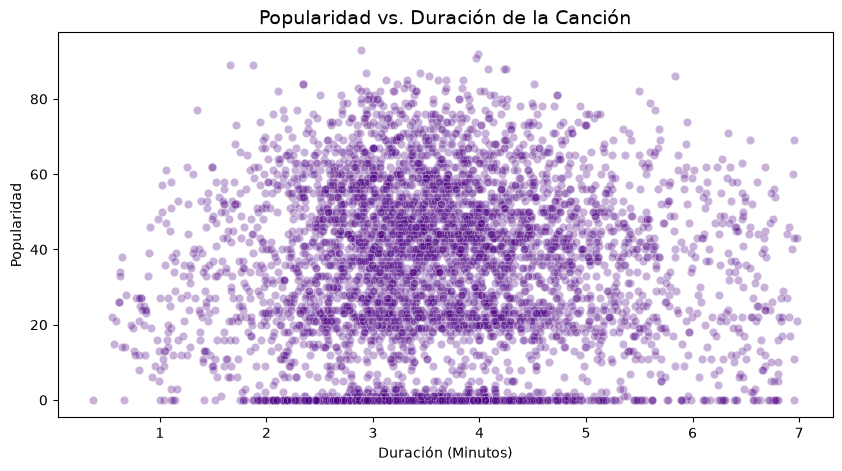

In [9]:
df_duracion = df[df['duration_ms'] < 420000].copy()
df_duracion['duration_min'] = df_duracion['duration_ms'] / 60000

plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_duracion.sample(5000, random_state=42), x='duration_min', y='popularity', alpha=0.3, color='indigo')
plt.title('Popularidad vs. Duración de la Canción', fontsize=14)
plt.xlabel('Duración (Minutos)')
plt.ylabel('Popularidad')
plt.show()

**Interpretación de la Duración (Implicaciones para el Modelo)**

*   A partir de los 5 minutos, la probabilidad de alcanzar una alta popularidad cae de forma drástica.
*   **Decisión técnica:** Para la fase de ingeniería de características, será estratégico convertir la variable continua `duration_ms` en categorías discretas (ej. "Corta", "Radio Edit", "Larga"). Esto le dará al algoritmo un atajo matemático directo para premiar las canciones que caen en la ventana de mayor éxito comercial.

### Análisis de Cardinalidad (Variables Categóricas)
Es crucial entender cuántos valores únicos existen en nuestras variables de texto para determinar cómo las transformaremos matemáticamente más adelante y detectar posibles anomalías en los registros.

In [10]:
columnas_texto = df.select_dtypes(include=['object'])

print("--- VALORES ÚNICOS POR COLUMNA (CARDINALIDAD) ---")
for col in columnas_texto.columns:
    unicos = df[col].nunique()
    print(f"{col}: {unicos} valores únicos")

total_filas = len(df)
tracks_unicos = df['track_id'].nunique()

print("\n--- ANÁLISIS DE DUPLICADOS ---")
print(f"Total de registros: {total_filas}")
print(f"IDs de canciones únicas: {tracks_unicos}")
if tracks_unicos < total_filas:
    print(f"Existen {total_filas - tracks_unicos} registros duplicados en el dataset.")

--- VALORES ÚNICOS POR COLUMNA (CARDINALIDAD) ---
track_id: 89741 valores únicos
artists: 31437 valores únicos
album_name: 46589 valores únicos
track_name: 73608 valores únicos
track_genre: 114 valores únicos

--- ANÁLISIS DE DUPLICADOS ---
Total de registros: 114000
IDs de canciones únicas: 89741
Existen 24259 registros duplicados en el dataset.


C:\Users\emmanuel.chavero\AppData\Local\Temp\ipykernel_15756\3808380060.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_texto = df.select_dtypes(include=['object'])


-**Interpretación de la Cardinalidad y Hallazgo Crítico:**

*   **Diversidad de Géneros:** El catálogo cuenta con exactamente 114 géneros musicales (`track_genre`). Esta es una cantidad ideal para que el algoritmo pueda segmentar el mercado de manera granular.
*   **Alerta de Duplicados (Data Leakage):** El análisis revela un problema severo en la estructura del dataset original. De las 114,000 filas totales, solo 89,741 corresponden a canciones únicas (`track_id`). Esto significa que tenemos **24,259 registros duplicados**.
*   **Razón probable:** Es altamente probable que una misma canción haya sido clasificada por Spotify en más de un género a la vez, generando una fila nueva por cada género asignado.
*   **Implicación para la Fase 3:** Esto es crítico. Si entrenamos un modelo de Machine Learning con datos duplicados, sufriremos de *Data Leakage* (fuga de datos), haciendo que el modelo parezca artificialmente bueno porque memorizó canciones repetidas. En la siguiente fase habrá que decidir como manejamos estos datos.

In [11]:
conteo_generos = df['track_genre'].value_counts()
pd.set_option('display.max_rows', 150)
print(conteo_generos)

pd.reset_option('display.max_rows')

track_genre
acoustic             1000
afrobeat             1000
alt-rock             1000
alternative          1000
ambient              1000
anime                1000
black-metal          1000
bluegrass            1000
blues                1000
brazil               1000
breakbeat            1000
british              1000
cantopop             1000
chicago-house        1000
children             1000
chill                1000
classical            1000
club                 1000
comedy               1000
country              1000
dance                1000
dancehall            1000
death-metal          1000
deep-house           1000
detroit-techno       1000
disco                1000
disney               1000
drum-and-bass        1000
dub                  1000
dubstep              1000
edm                  1000
electro              1000
electronic           1000
emo                  1000
folk                 1000
forro                1000
french               1000
funk                 1000


In [12]:
generos_por_cancion = df.groupby(['track_id', 'track_name'])['track_genre'].agg(list).reset_index()

generos_por_cancion['cantidad_generos'] = generos_por_cancion['track_genre'].apply(len)

canciones_multi_genero = generos_por_cancion[generos_por_cancion['cantidad_generos'] > 1].sort_values(by='cantidad_generos', ascending=False)

print(f"Total de canciones únicas con múltiples géneros: {len(canciones_multi_genero)}")
print("\nTop 10 canciones repetidas y sus géneros asignados:")
display(canciones_multi_genero.head(10))

Total de canciones únicas con múltiples géneros: 16641

Top 10 canciones repetidas y sus géneros asignados:


,track_id,track_name,track_genre,cantidad_generos
74275,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,"[blues, country, folk, j-pop, j-rock, power-po...",9
25739,2Ey6v4Sekh3Z0RUSISRosD,Layla,"[blues, british, country, folk, hard-rock, psy...",8
31723,2kkvB3RNRzwjFdGhaUA0tz,Layla,"[blues, british, country, folk, hard-rock, psy...",8
64109,5ZsAhuQ24mWHiduaxJqnhW,Udd Gaye,"[edm, hip-hop, indian, indie-pop, indie, pop-f...",7
65253,5ftfVzSLIi5ZxYdNbRtf41,Never Gonna Give You Up,"[alt-rock, alternative, blues, garage, punk-ro...",7
5012,0RSGPiykniIg8m7JhiAVv7,Aisi Raaton,"[indian, indie-pop, indie, k-pop, pop-film, si...",7
69227,61202Zzk9rk4bPMZLh2gr6,Trouble No More,"[blues, country, folk, hard-rock, j-rock, sing...",7
88605,7tbzfR8ZvZzJEzy6v0d6el,Liggi,"[edm, hip-hop, indian, indie-pop, indie, pop-f...",7
33705,2vU6bm5hVF2idVknGzqyPL,Christmas (Baby Please Come Home),"[alt-rock, alternative, metal, punk-rock, punk...",7
7396,0e5LcankE0UyJUuCoq1uH2,The Joker,"[blues, country, folk, hard-rock, psych-rock, ...",7


### Evidencia Empírica de Duplicidad Multigénero

*   **Volumen Afectado:** Existen 16,641 canciones que aparecen más de una vez en el catálogo debido a clasificaciones simultáneas.
*   **Casos Extremos:** El caso más evidente es la pista "Baby Blue - Remastered 2010", la cual fue insertada 9 veces en el *dataset* bajo géneros musicalmente incompatibles entre sí (como *blues*, *j-pop* y *country*). "Never Gonna Give You Up" también sufre este fenómeno apareciendo en 7 categorías distintas.
*   **Impacto Predictivo:** Si el modelo de Machine Learning ve "Baby Blue" 9 veces durante su entrenamiento con exactamente las mismas características acústicas, memorizará la canción en lugar de aprender patrones generales (*Overfitting* o Sobreajuste).
*   **Resolución:** En la etapa de Preparación de Datos, eliminaremos las filas duplicadas basándonos en el `track_id`, conservando únicamente la primera aparición de cada canción y descartando las redundancias.

In [13]:
indice_max_popularidad = df['popularity'].idxmax()
hit_absoluto = df.loc[indice_max_popularidad]

print("--- EL MAYOR ÉXITO INDIVIDUAL ---")
print(f"Artista: {hit_absoluto['artists']}")
print(f"Álbum: {hit_absoluto['album_name']}")
print(f"Canción: {hit_absoluto['track_name']}")
print(f"Puntuación: {hit_absoluto['popularity']}/100\n")

artistas_frecuentes = df['artists'].value_counts()
artistas_validos = artistas_frecuentes[artistas_frecuentes >= 5].index

top_artistas = df[df['artists'].isin(artistas_validos)].groupby('artists')['popularity'].mean()
top_artistas = top_artistas.sort_values(ascending=False).head(5)

print("--- TOP 5 ARTISTAS (PROMEDIO MÁS ALTO) ---")
print(top_artistas)
print("\n")

albumes_frecuentes = df['album_name'].value_counts()
albumes_validos = albumes_frecuentes[albumes_frecuentes >= 3].index

top_albumes = df[df['album_name'].isin(albumes_validos)].groupby('album_name')['popularity'].mean()
top_albumes = top_albumes.sort_values(ascending=False).head(5)

print("--- TOP 5 ÁLBUMES (PROMEDIO MÁS ALTO) ---")
print(top_albumes)

--- EL MAYOR ÉXITO INDIVIDUAL ---
Artista: Sam Smith;Kim Petras
Álbum: Unholy (feat. Kim Petras)
Canción: Unholy (feat. Kim Petras)
Puntuación: 100/100

--- TOP 5 ARTISTAS (PROMEDIO MÁS ALTO) ---
artists
Olivia Rodrigo             87.400000
Bad Bunny                  87.083333
Bad Bunny;Jhayco           87.000000
The Chainsmokers;Halsey    84.000000
Marshmello;Khalid          84.000000
Name: popularity, dtype: float64


--- TOP 5 ÁLBUMES (PROMEDIO MÁS ALTO) ---
album_name
La Bachata                                                             98.000000
I Ain’t Worried (Music From The Motion Picture "Top Gun: Maverick")    96.000000
I'm Good (Blue)                                                        91.000000
L3tra                                                                  90.500000
Un Verano Sin Ti                                                       90.142857
Name: popularity, dtype: float64


**Interpretación de los Líderes de Popularidad:**

*   **Éxito Absoluto:** La canción "Unholy" de Sam Smith y Kim Petras es el registro que alcanzó el tope métrico de la plataforma (100/100) en esta extracción.
*   **Dominio del Mercado (Artistas):** Al promediar los catálogos (con al menos 5 pistas), la plataforma está dominada por el Pop contemporáneo y el Reggaetón, con **Olivia Rodrigo** (87.4) y **Bad Bunny** (87.08) a la cabeza.
*   **Anomalía en Metadatos (Colaboraciones):** El sistema registra las colaboraciones fusionando los nombres (ej. `Bad Bunny;Jhayco` o `The Chainsmokers;Halsey`). En un entorno de negocio real, esta estructura diluye las estadísticas individuales de un artista y obliga a separar los nombres (Data Cleaning) para medir el impacto real de cada cantante.
*   **Consistencia de Álbumes:** Discos de música latina ("La Bachata", "Un Verano Sin Ti") y bandas sonoras ("Top Gun: Maverick") mantienen un promedio de éxito masivo por encima de los 90 puntos, demostrando que no solo tienen un "hit", sino que el álbum entero es consumido por los usuarios.

### Análisis de Contenido Explícito
Nos interesa descubrir si las canciones con letras explícitas (`explicit` = True) tienen un rendimiento diferente en términos de popularidad en comparación con las canciones aptas para todo público. Utilizaremos un diagrama de caja (boxplot) para comparar sus distribuciones.

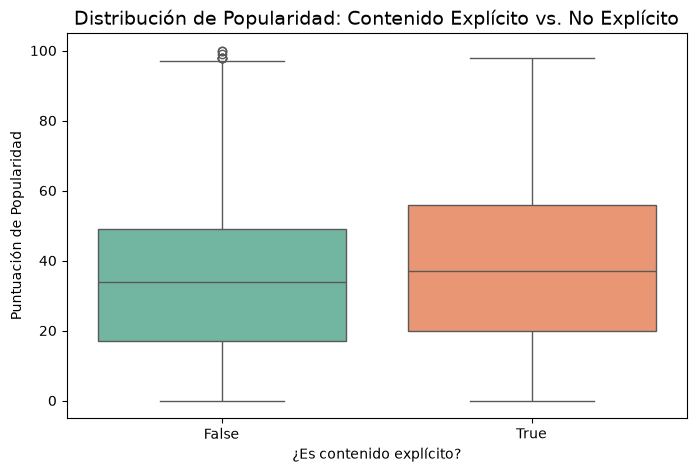

Promedio de popularidad:
No Explícito (False): 32.94
Explícito (True): 36.45


In [14]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='explicit', y='popularity', hue='explicit', palette='Set2', legend=False)
plt.title('Distribución de Popularidad: Contenido Explícito vs. No Explícito', fontsize=14)
plt.xlabel('¿Es contenido explícito?')
plt.ylabel('Puntuación de Popularidad')
plt.show()

promedios_explicito = df.groupby('explicit')['popularity'].mean()
print("Promedio de popularidad:")
print(f"No Explícito (False): {promedios_explicito[False]:.2f}")
print(f"Explícito (True): {promedios_explicito[True]:.2f}")

**Interpretación del Impacto Explícito:**
*   Aunque el promedio general del dataset es bajo, las canciones con contenido explícito tienden a tener una popularidad promedio ligeramente superior y una mediana más alta que las canciones no explícitas.
*   Esto puede deberse a que los géneros que actualmente dominan las listas de éxitos mundiales (como el hip-hop, rap o reggaetón) suelen contener lenguaje explícito de forma natural.
*   **Implicación para el Modelo:** La variable `explicit` ya está en formato booleano, pero en la Fase 3 la convertiremos a formato numérico (0 y 1) para que el algoritmo pueda ponderarla correctamente.

### Conclusión General de la Fase 2

Tras un Análisis Exploratorio de Datos (EDA) hemos perfilado el comportamiento del catálogo y detectado anomalías que definirán la estrategia de nuestro modelo.

**Resumen de Hallazgos:**
*   **Falta de Linealidad:** Las variables acústicas puras (como energía o bailabilidad) no presentan una correlación lineal directa con la popularidad, lo que descarta modelos simples como la regresión lineal y orienta el proyecto hacia algoritmos complejos capaces de capturar patrones no lineales.
*   **Interacción Multidimensional (Mapa de Emociones):** Variables como positividad (`valence`) e intensidad (`energy`) operan de forma conjunta; el éxito comercial se concentra en cuadrantes específicos y en los márgenes se detectaron concentraciones anómalas de pistas con popularidad cero (audios corruptos o sin métricas).
*   **Impacto Categórico y de Metadatos:** Los metadatos comerciales y géneros musicales (`track_genre`, `explicit`) muestran diferencias estadísticas claras en la popularidad promedio, a diferencia de variables planas como la tonalidad (`key`) o el modo (`mode`).
*   **Sesgo (Data Leakage):** La validación estadística confirmó un balance forzado de exactamente 1,000 canciones por cada uno de los 114 géneros, generando 24,259 registros duplicados (con pistas repetidas hasta 9 veces) que provocarían *overfitting* si no se corrigen.
*   **Anomalías de Rango:** La inspección de dispersión y percentiles reveló valores extremos e irreales en la duración de las pistas, con un máximo superior a 87 minutos (`duration_ms`).




## Fase 3: Preparación de los Datos

En esta fase transformamos el dataset crudo en una matriz de características limpia y numérica, aplicando las decisiones técnicas que el EDA de la Fase 2 dejó establecidas: eliminación de columnas redundantes, deduplicación de canciones, tratamiento de outliers y de los registros con popularidad nula, codificación de variables categóricas y creación de nuevas características.

In [15]:
df_clean = df.copy()

df_clean = df_clean.drop(columns=['Unnamed: 0'])

nulos_antes = df_clean.isnull().any(axis=1).sum()
df_clean = df_clean.dropna()
print(f"Registros con nulos eliminados: {nulos_antes}")

filas_antes = len(df_clean)
df_clean = df_clean.drop_duplicates(subset='track_id', keep='first')
print(f"Registros duplicados eliminados: {filas_antes - len(df_clean)}")

filas_antes = len(df_clean)
df_clean = df_clean[df_clean['duration_ms'] < 420000]
print(f"Outliers de duración eliminados: {filas_antes - len(df_clean)}")

df_antes_ceros = df_clean.copy()
filas_antes = len(df_clean)
df_clean = df_clean[df_clean['popularity'] > 0]
print(f"Registros con popularidad = 0 eliminados: {filas_antes - len(df_clean)}")

print(f"\nDataset limpio: {df_clean.shape[0]} filas x {df_clean.shape[1]} columnas")

Registros con nulos eliminados: 1
Registros duplicados eliminados: 24259
Outliers de duración eliminados: 3311
Registros con popularidad = 0 eliminados: 9196

Dataset limpio: 77233 filas x 20 columnas


**Decisiones de Limpieza y su Justificación:**

1.  **`Unnamed: 0` eliminada:** índice redundante sin valor analítico, confirmado en la Fase 2.
2.  **Deduplicación por `track_id`:** es el paso más crítico. Si una misma canción quedara en entrenamiento y prueba a la vez, el modelo la "memorizaría" y las métricas serían artificialmente optimistas (*data leakage*).
3.  **Umbral de duración (7 min):** coherente con lo observado en el EDA — a partir de ~5 minutos la probabilidad de alta popularidad colapsa, y los valores extremos (>80 min) corresponden a contenido no musical.
4.  **Exclusión de `popularity = 0`:** según el análisis de la Fase 2, estos registros representan pistas sin exposición o con métricas faltantes, no un atributo acústico real. Entrenar con ellos enseñaría al modelo a predecir "fracaso" por razones ajenas a la música. El impacto de esta decisión se evalúa empíricamente al final del taller.

In [16]:

df_clean['explicit'] = df_clean['explicit'].astype(int)

df_clean['duration_min'] = df_clean['duration_ms'] / 60000

df_clean['valence_energy'] = df_clean['valence'] * df_clean['energy']

df_modelo = df_clean.drop(columns=['track_id', 'artists', 'album_name', 'track_name', 'duration_ms'])

df_modelo = pd.get_dummies(df_modelo, columns=['track_genre'], prefix='genre')

print(f"Matriz de características: {df_modelo.shape[0]} filas x {df_modelo.shape[1]} columnas")
df_modelo.head()

Matriz de características: 77233 filas x 129 columnas


,popularity,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,...,genre_spanish,genre_study,genre_swedish,genre_synth-pop,genre_tango,genre_techno,genre_trance,genre_trip-hop,genre_turkish,genre_world-music
0,73,0,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,...,False,False,False,False,False,False,False,False,False,False
1,55,0,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,...,False,False,False,False,False,False,False,False,False,False
2,57,0,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,...,False,False,False,False,False,False,False,False,False,False
3,71,0,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,...,False,False,False,False,False,False,False,False,False,False
4,82,0,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,...,False,False,False,False,False,False,False,False,False,False


**Decisiones de Codificación (Encoding):**

*   **`explicit` → int (0/1):** codificación binaria directa.
*   **`track_genre` → One-Hot Encoding:** 114 géneros nominales sin orden natural; una dummy por género.
*   **Textos de alta cardinalidad descartados:** `artists` (31k únicos), `album_name` y `track_name` (73k) — su one-hot explotaría en dimensiones y sobreajustaría; la señal categórica ya la captura el género.
*   **Sin escalamiento global:** los modelos basados en árboles dividen por umbrales y son invariantes a la escala. Solo los modelos que lo necesitan (KNN por distancias, Ridge por regularización L2) se escalan dentro de su propio Pipeline — dentro de cada pliegue de CV para evitar fuga de información.

In [17]:
from sklearn.model_selection import train_test_split

X = df_modelo.drop(columns=['popularity'])
y = df_modelo['popularity']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Entrenamiento: {X_train.shape[0]} muestras")
print(f"Prueba:        {X_test.shape[0]} muestras")
print(f"Características: {X_train.shape[1]}")

Entrenamiento: 61786 muestras
Prueba:        15447 muestras
Características: 128


## Fase 4: Modelado

A través del EDA se concluyó que no existen relaciones lineales fuertes con la popularidad. Comparamos los **modelos de regresión de la unidad** más dos ensambles avanzados (el objetivo es predecir el puntaje 0–100):

| Modelo | Rol | Justificación |
|--------|-----|---------------|
| **Regresión Lineal** | Baseline | Modelo más simple; verifica la hipótesis de la Fase 2 (los lineales rendirán mal). |
| **Ridge** | Lineal regularizado | Penaliza coeficientes grandes (L2); útil con 114 dummies correlacionadas. |
| **KNN** | Basado en distancia | Compara cada canción con sus "vecinas" más similares; **requiere escalado** (las distancias se distorsionan con magnitudes dispares). |
| **Árbol de Decisión** | No lineal interpretable | Particiones por reglas; el modelo flexible más simple de la unidad. |
| **Random Forest** | Ensamble avanzado | Combina muchos árboles; robusto a outliers, entrega importancia de características. |
| **Gradient Boosting** | Ensamble avanzado | Corrige errores iterativamente; suele superar a Random Forest en tabulares. |

**Criterio de comparación:** validación cruzada de 5 pliegues sobre el conjunto de entrenamiento (el conjunto de prueba permanece intacto hasta la Fase 5). Se compara el R² promedio y su desviación estándar.

In [18]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

modelos = {
    'Regresión Lineal': LinearRegression(),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'KNN': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10, n_jobs=1)),
    'Árbol de Decisión': DecisionTreeRegressor(max_depth=10, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=15,
                                           n_jobs=1, random_state=42),
    'Gradient Boosting': HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1,
                                                       random_state=42)
}
resultados_cv = {}
for nombre, modelo in modelos.items():
    scores = cross_val_score(modelo, X_train, y_train, cv=5,
                             scoring='r2', n_jobs=1)
    resultados_cv[nombre] = (scores.mean(), scores.std())
    print(f"{nombre:20s} | R² CV: {scores.mean():.4f} ± {scores.std():.4f}")

Regresión Lineal     | R² CV: 0.4395 ± 0.0085


Ridge                | R² CV: 0.4395 ± 0.0085


KNN                  | R² CV: 0.4422 ± 0.0113


Árbol de Decisión    | R² CV: 0.2022 ± 0.0037


Random Forest        | R² CV: 0.2980 ± 0.0027


Gradient Boosting    | R² CV: 0.4747 ± 0.0083


**Lectura de la Validación Cruzada:**

*   **Gradient Boosting lidera (R² ≈ 0.475):** el único modelo que supera claramente a todos.
*   **KNN sorprende (R² ≈ 0.442):** segundo lugar, apenas por sobre los lineales — comparar cada canción con sus vecinas acústicas cercanas sí aporta señal.
*   **Regresión Lineal y Ridge idénticas (R² ≈ 0.440):** la regularización L2 no cambia el resultado; el género en one-hot ya entrega señal lineal fuerte (cada dummy "hereda" la popularidad promedio de su género).
*   **Árbol de Decisión solo (R² ≈ 0.202):** muy inferior a sus ensambles — un solo árbol con profundidad limitada generaliza mal aquí.
*   **Random Forest flojo (R² ≈ 0.298):** confirma que no basta con "poner árboles"; la forma de combinarlos importa.
*   **Estabilidad:** desviaciones estándar de 0.003–0.011 indican que las diferencias entre modelos son reales y no azar del muestreo.

## Fase 5: Evaluación

Evaluamos los modelos entrenados sobre el **conjunto de prueba** (datos nunca vistos), utilizando tres métricas complementarias:

*   **MAE** (Error Absoluto Medio): desviación promedio de la predicción en puntos de popularidad — directamente interpretable para el negocio.
*   **RMSE** (Raíz del Error Cuadrático Medio): penaliza más los errores grandes, revelando si el modelo comete fallos graves.
*   **R²** (Coeficiente de Determinación): proporción de la varianza de la popularidad explicada por el modelo (1.0 = perfecto, 0 = no mejor que la media).

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

resultados = []
predicciones = {}

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    predicciones[nombre] = pred
    resultados.append({
        'Modelo': nombre,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    })

df_resultados = pd.DataFrame(resultados).set_index('Modelo')
display(df_resultados.round(3))

nombre_mejor = df_resultados['R2'].idxmax()
mejor_modelo = modelos[nombre_mejor]
print(f"\nMejor modelo según R² en prueba: {nombre_mejor}")

,MAE,RMSE,R2
Modelo,,,
Regresión Lineal,9.732,13.509,0.446
Ridge,9.732,13.509,0.446
KNN,9.208,13.359,0.458
Árbol de Decisión,12.664,16.068,0.216
Random Forest,11.668,15.049,0.312
Gradient Boosting,9.250,12.961,0.490



Mejor modelo según R² en prueba: Gradient Boosting


**Interpretación de las métricas para el negocio:**

*   **MAE en palabras simples:** en promedio, el mejor modelo se equivoca en ±9.2 puntos de popularidad — si estima un 60, el valor real suele estar entre ~51 y ~69.
*   **RMSE > MAE (12.96 vs. 9.25):** la brecha revela que existen errores ocasionalmente grandes que el RMSE penaliza — el modelo falla feo en una minoría de casos, coherente con la heterogeneidad entre géneros que muestra la auditoría por subgrupos.
*   **R² = 0.490:** el modelo explica ~49% de la variación de la popularidad. Supera el umbral mínimo de 0.30 que la guía sugiere para considerar usable un modelo, pero está lejos de ser determinante — sirve como brújula para priorizar, no como oráculo.

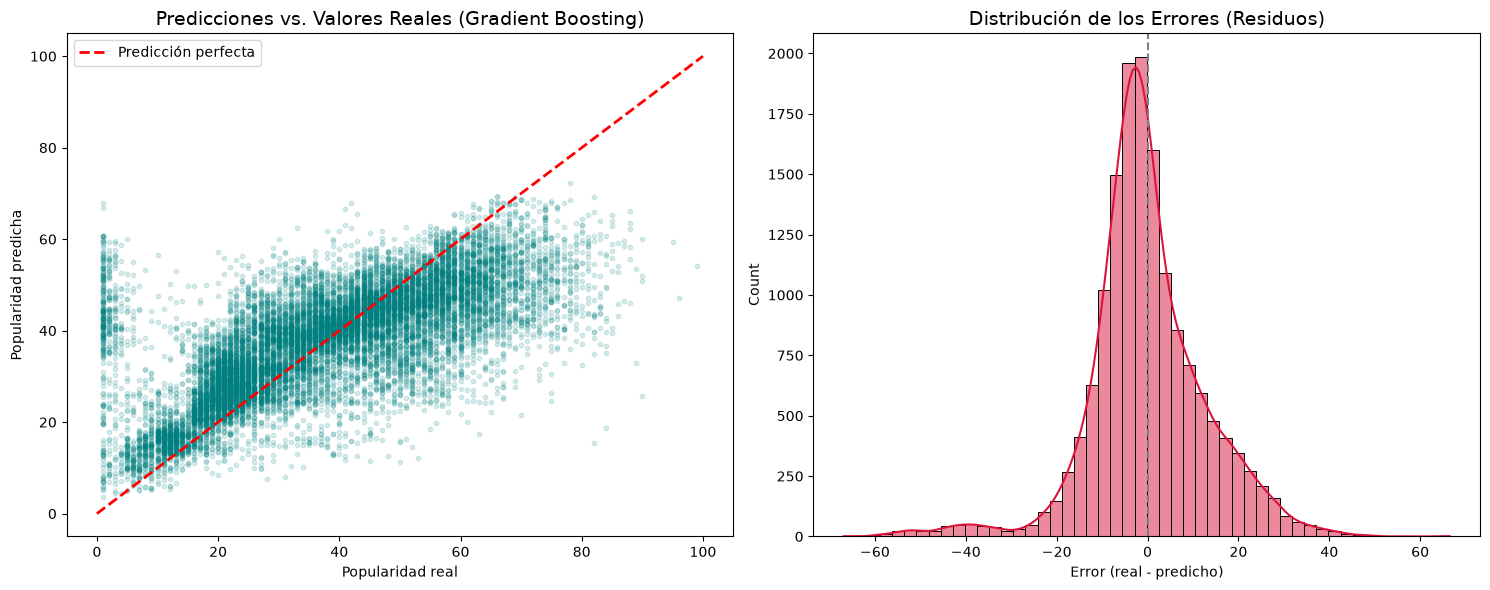

In [20]:
y_pred = predicciones[nombre_mejor]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(y_test, y_pred, alpha=0.15, s=10, color='teal')
axes[0].plot([0, 100], [0, 100], 'r--', linewidth=2, label='Predicción perfecta')
axes[0].set_title(f'Predicciones vs. Valores Reales ({nombre_mejor})', fontsize=14)
axes[0].set_xlabel('Popularidad real')
axes[0].set_ylabel('Popularidad predicha')
axes[0].legend()

residuos = y_test - y_pred
sns.histplot(residuos, bins=50, kde=True, ax=axes[1], color='crimson')
axes[1].axvline(x=0, color='gray', linestyle='--')
axes[1].set_title('Distribución de los Errores (Residuos)', fontsize=14)
axes[1].set_xlabel('Error (real - predicho)')

plt.tight_layout()
plt.show()

**Interpretación de los gráficos de verificación:**

*   **Predicción vs. real:** la nube sigue la diagonal, pero con dispersión amplia — el modelo comprime sus estimaciones hacia el rango medio (~20–60) y subestima los valores extremos: a los verdaderos hits (90+) les asigna popularidades más modestas. Es el fenómeno de *regresión a la media*.
*   **Residuos:** distribución aproximadamente centrada en 0 — el modelo no tiene sesgo sistemático hacia arriba ni hacia abajo. La cola derecha confirma que los errores más grandes corresponden a éxitos subestimados, conectando con el costo de negocio identificado en la Fase 1.

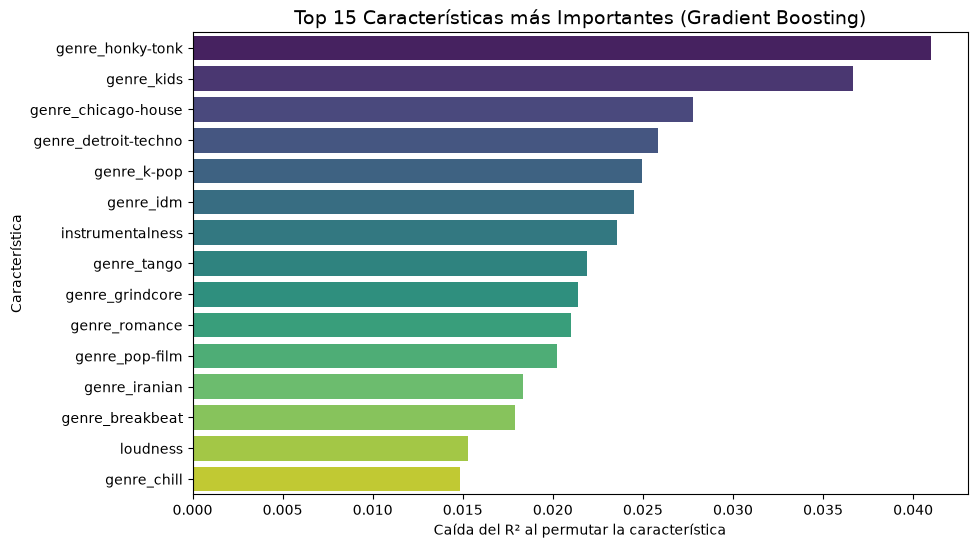

In [21]:
from sklearn.inspection import permutation_importance

resultado_perm = permutation_importance(mejor_modelo, X_test, y_test,
                                        n_repeats=10, random_state=42, n_jobs=1)
importancias = pd.Series(resultado_perm.importances_mean, index=X.columns)
top_15 = importancias.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_15.values, y=top_15.index, hue=top_15.index,
            legend=False, palette='viridis')
plt.title(f'Top 15 Características más Importantes ({nombre_mejor})', fontsize=14)
plt.xlabel('Caída del R² al permutar la característica')
plt.ylabel('Característica')
plt.show()

### Diagnóstico de Overfitting y Underfitting

Un buen modelo generaliza: rinde similar en datos nuevos que en entrenamiento. Para verificarlo usamos dos evidencias:

*   **Brecha train/test:** si el R² de entrenamiento supera por mucho al de prueba → *overfitting* (memorizó el ruido). Si ambos son bajos → *underfitting* (el modelo es demasiado simple).
*   **Curva de aprendizaje:** rendimiento según el tamaño del conjunto de entrenamiento. Curvas convergentes y altas = buen ajuste; brecha persistente = varianza; ambas planas y bajas = sesgo.

Regresión Lineal: R² train = 0.443 | R² test = 0.446 | brecha = -0.003
Ridge: R² train = 0.443 | R² test = 0.446 | brecha = -0.003


KNN: R² train = 0.548 | R² test = 0.458 | brecha = 0.090
Árbol de Decisión: R² train = 0.225 | R² test = 0.216 | brecha = 0.009


Random Forest: R² train = 0.331 | R² test = 0.312 | brecha = 0.019


Gradient Boosting: R² train = 0.539 | R² test = 0.490 | brecha = 0.049


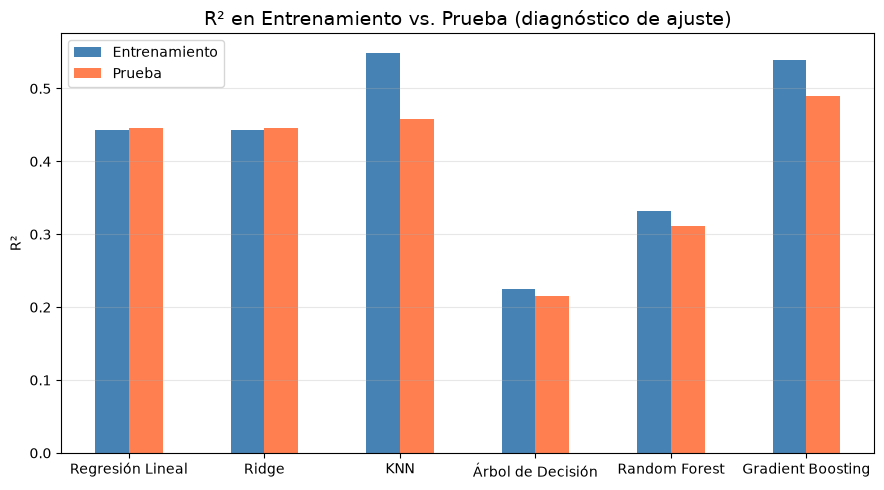

In [22]:

comparacion = []
for nombre, modelo in modelos.items():
    r2_train = modelo.score(X_train, y_train)
    r2_test = modelo.score(X_test, y_test)
    comparacion.append({'Modelo': nombre,
                        'Entrenamiento': r2_train,
                        'Prueba': r2_test})
    print(f"{nombre}: R² train = {r2_train:.3f} | R² test = {r2_test:.3f} | brecha = {r2_train - r2_test:.3f}")

df_comp = pd.DataFrame(comparacion).set_index('Modelo')
df_comp.plot(kind='bar', figsize=(9, 5), color=['steelblue', 'coral'])
plt.title('R² en Entrenamiento vs. Prueba (diagnóstico de ajuste)', fontsize=14)
plt.ylabel('R²')
plt.xlabel('')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

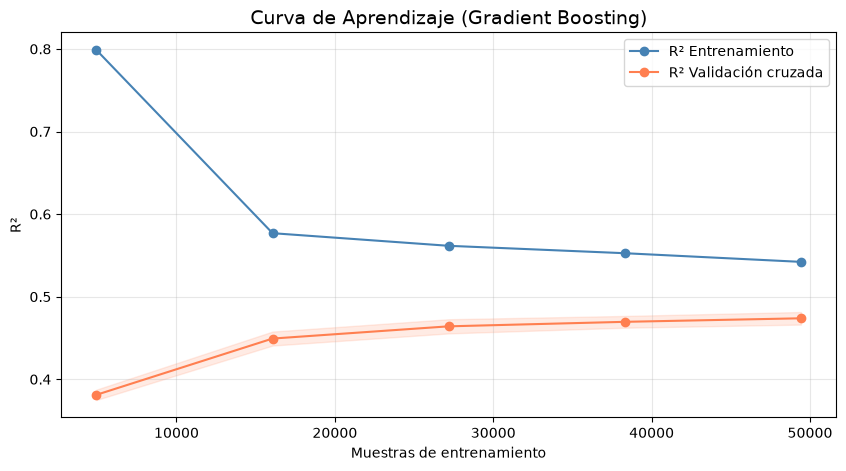

In [23]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    mejor_modelo, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 5), cv=5,
    scoring='r2', n_jobs=1, random_state=42)

media_train = train_scores.mean(axis=1)
media_val = val_scores.mean(axis=1)
std_val = val_scores.std(axis=1)

plt.figure(figsize=(10, 5))
plt.plot(train_sizes, media_train, 'o-', color='steelblue', label='R² Entrenamiento')
plt.plot(train_sizes, media_val, 'o-', color='coral', label='R² Validación cruzada')
plt.fill_between(train_sizes, media_val - std_val, media_val + std_val,
                 alpha=0.15, color='coral')
plt.title(f'Curva de Aprendizaje ({nombre_mejor})', fontsize=14)
plt.xlabel('Muestras de entrenamiento')
plt.ylabel('R²')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

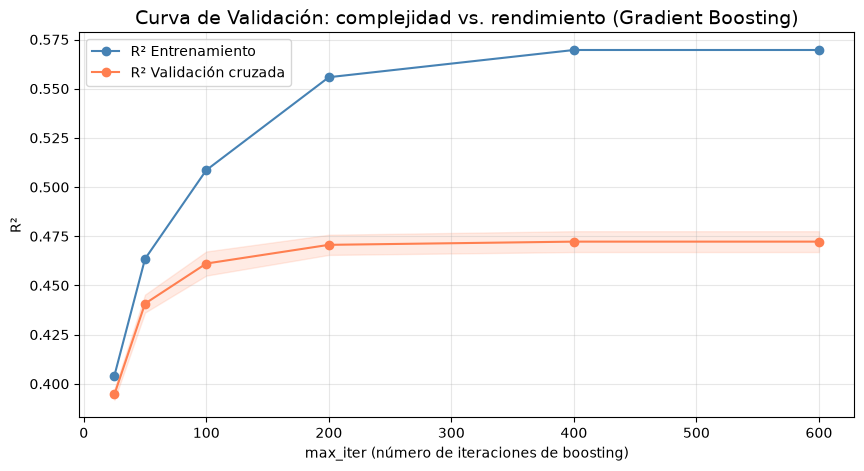

In [24]:
from sklearn.model_selection import validation_curve

param_range = [25, 50, 100, 200, 400, 600]

train_scores, val_scores = validation_curve(
    HistGradientBoostingRegressor(random_state=42),
    X_train, y_train,
    param_name='max_iter', param_range=param_range,
    cv=3, scoring='r2', n_jobs=1)

media_train = train_scores.mean(axis=1)
media_val = val_scores.mean(axis=1)
std_val = val_scores.std(axis=1)

plt.figure(figsize=(10, 5))
plt.plot(param_range, media_train, 'o-', color='steelblue', label='R² Entrenamiento')
plt.plot(param_range, media_val, 'o-', color='coral', label='R² Validación cruzada')
plt.fill_between(param_range, media_val - std_val, media_val + std_val,
                 alpha=0.15, color='coral')
plt.title('Curva de Validación: complejidad vs. rendimiento (Gradient Boosting)', fontsize=14)
plt.xlabel('max_iter (número de iteraciones de boosting)')
plt.ylabel('R²')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Interpretación del diagnóstico de ajuste:**

*   **Brecha train/test por modelo:**
    *   *Regresión Lineal:* brecha ≈ 0 (0.443 train vs 0.446 test) — generaliza perfectamente; su límite es de **sesgo** (modelo demasiado simple para capturar más estructura).
    *   *Random Forest:* brecha 0.019, pequeña — con `max_depth=15` no logra memorizar de forma severa; su problema no es overfitting sino rendimiento global bajo en este problema dominado por 114 variables binarias dispersas.
    *   *Gradient Boosting:* brecha 0.049 (0.539 vs 0.490) — la mayor de las tres pero modesta; varianza controlada y mejor R² absoluto. Es el mejor equilibrio sesgo-varianza del experimento.
*   **Curva de aprendizaje (Gradient Boosting):** con ~4.000 muestras el gap train/validación era de 0.47 (overfitting severo por poca data); al llegar a ~50.000 muestras el gap se reduce a ~0.08 y la curva de validación **aún asciende levemente** (0.35 → 0.47) aunque ya se aplana. Lectura: más datos entregarían una mejora marginal, pero la forma sugiere que el modelo se acerca al **techo informativo de las características actuales** — para mejorar sustancialmente harían falta mejores variables (metadatos de promoción, antigüedad, sello), no solo más filas.
*   **Curva de validación (complejidad vs. rendimiento):** se distinguen las tres zonas clásicas. Con `max_iter` ≤ 50 el modelo está en **underfitting** (ambas curvas bajas: ~0.40). Entre 100 y 200 la validación alcanza su meseta (~0.47) — **zona óptima**. Desde ~200 en adelante, el R² de entrenamiento sigue subiendo (0.556 → 0.570) mientras la validación se estanca en 0.472: **inicio de overfitting** — agregar más iteraciones solo memoriza ruido. Nuestra elección de `max_iter=200` queda validada empíricamente: está justo en el borde donde la complejidad deja de aportar generalización.

### Variante de Clasificación por Rangos (alternativa de la Fase 1)

La Fase 1 dejaba abierta la opción de reformular el problema como clasificación agrupando la popularidad por rangos. La implementamos aquí para aplicar las **métricas de clasificación de la unidad** (matriz de confusión, precision, recall, F1) y comparar conceptualmente ambos enfoques:

*   **Baja (1–33):** pistas con difusión limitada.
*   **Media (34–66):** difusión moderada.
*   **Alta (67–100):** candidatas a éxito comercial.

Usamos el **Árbol de Decisión**, el modelo de clasificación trabajado en la unidad.

--- Distribución de clases en entrenamiento ---
popularity
Baja     27137
Media    31049
Alta      3600



--- Reporte de Clasificación ---
              precision    recall  f1-score   support

        Alta       0.00      0.00      0.00       883
        Baja       0.85      0.38      0.52      6781
       Media       0.59      0.95      0.73      7783

    accuracy                           0.64     15447
   macro avg       0.48      0.44      0.42     15447
weighted avg       0.67      0.64      0.60     15447



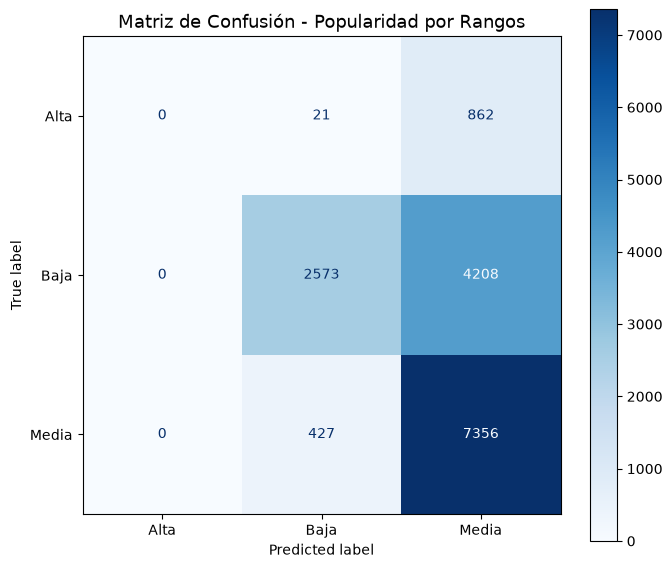

In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

bins = [0, 33, 66, 100]
etiquetas = ['Baja', 'Media', 'Alta']
y_train_cat = pd.cut(y_train, bins=bins, labels=etiquetas)
y_test_cat = pd.cut(y_test, bins=bins, labels=etiquetas)

print("--- Distribución de clases en entrenamiento ---")
print(y_train_cat.value_counts().sort_index().to_string())

clf = DecisionTreeClassifier(max_depth=10, random_state=42)
clf.fit(X_train, y_train_cat)
pred_cat = clf.predict(X_test)

print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test_cat, pred_cat, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test_cat, pred_cat, ax=ax, cmap='Blues')
plt.title('Matriz de Confusión - Popularidad por Rangos', fontsize=13)
plt.tight_layout()
plt.show()

**Interpretación de la variante de clasificación — un caso real del "accuracy engañoso":**

*   **Accuracy 0.64 pero recall 0.00 en la clase que importa:** el Árbol obtuvo 64% de aciertos globales... **sin predecir ni una sola canción de popularidad "Alta"** (recall = 0.00, precision indefinida). Es exactamente el fenómeno del taller de la unidad (accuracy 92% / recall 15%): la métrica global oculta que el modelo es inútil para detectar éxitos.
*   **Costo de negocio:** según el análisis de la Fase 1, el falso negativo (hit no detectado) es el error más caro — y este clasificador dejaría escapar el 100% de los éxitos reales. Un modelo "correcto" estadísticamente sería un desastre comercial.
*   **Causa — desbalance de clases:** "Alta" representa apenas ~6% del entrenamiento (3.600 de 61.786 pistas). El árbol minimiza su error ignorando la clase minoritaria.
*   **La matriz lo muestra todo:** la columna "Alta" está vacía — todas sus instancias reales fueron absorbidas por "Media". Las confusiones restantes son entre clases adyacentes, patrón esperado de una variable ordinal discretizada.
*   **Regresión vs. clasificación:** este resultado refuerza la elección de regresión como enfoque principal — la granularidad del puntaje 0–100 aprovecha mejor la señal disponible. Para que la clasificación fuese viable habría que tratar el desbalance (pesos de clase, remuestreo o umbrales de negocio más realistas), lo que se propone como trabajo futuro.

### Auditoría por Subgrupos (evaluación ética del desempeño)

Una métrica global puede esconder que el modelo funciona bien para unos segmentos y mal para otros. Siguiendo el criterio de auditoría de la unidad, desglosamos el error del mejor modelo por subgrupos del catálogo: contenido explícito, duración y género musical.

--- MAE por contenido explícito ---
explicit
No explícita     9.15
Explícita       10.30

--- MAE por duración de la canción ---
rango_duracion
<3 min      8.54
3-4 min    10.25
>4 min      8.76


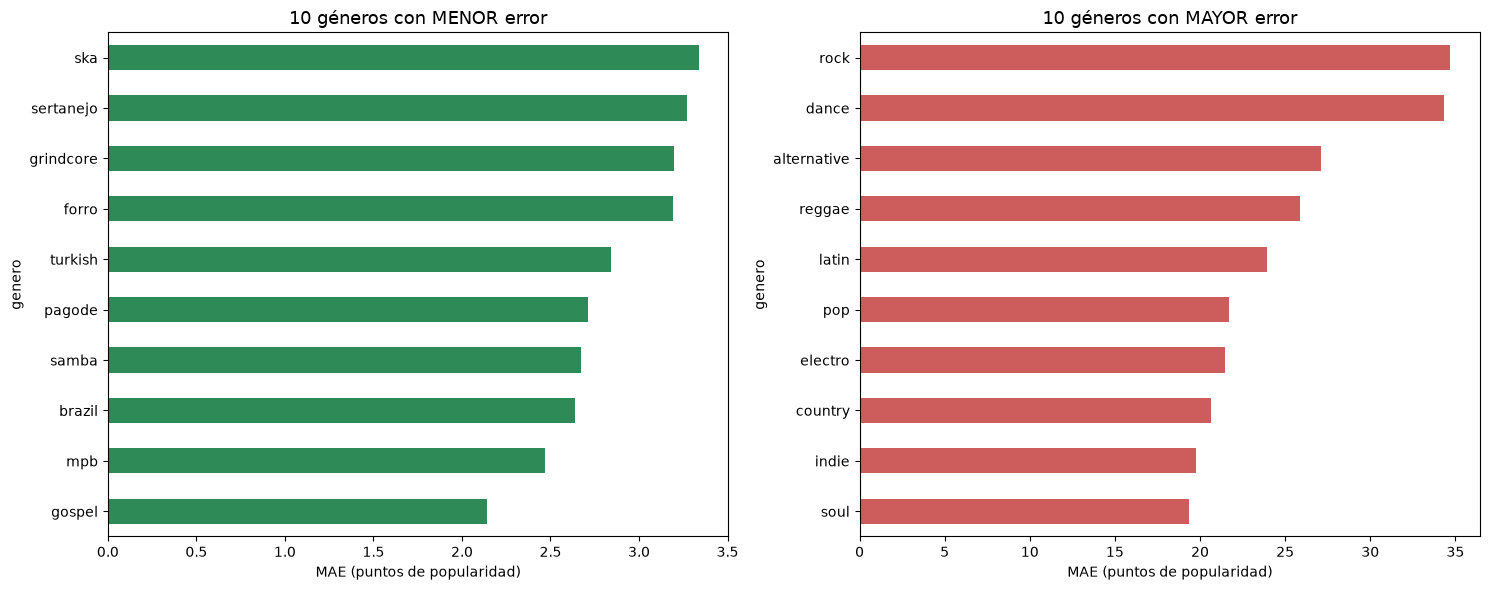


Brecha de error entre el mejor y el peor género: 32.57 puntos de popularidad


In [26]:

df_eval = X_test.copy()
df_eval['error_abs'] = np.abs(y_test.values - y_pred)

print("--- MAE por contenido explícito ---")
print(df_eval.groupby('explicit')['error_abs'].mean().round(2)
      .rename({0: 'No explícita', 1: 'Explícita'}).to_string())

df_eval['rango_duracion'] = pd.cut(df_eval['duration_min'], bins=[0, 3, 4, 7],
                                 labels=['<3 min', '3-4 min', '>4 min'])
print("\n--- MAE por duración de la canción ---")
print(df_eval.groupby('rango_duracion', observed=True)['error_abs']
      .mean().round(2).to_string())

cols_genero = X_test.filter(like='genre_').columns
df_eval['genero'] = (X_test[cols_genero].idxmax(axis=1)
                     .str.replace('genre_', '', regex=False))
mae_genero = df_eval.groupby('genero')['error_abs'].mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
mae_genero.head(10).sort_values().plot(kind='barh', ax=axes[0], color='seagreen')
axes[0].set_title('10 géneros con MENOR error', fontsize=13)
axes[0].set_xlabel('MAE (puntos de popularidad)')
mae_genero.tail(10).plot(kind='barh', ax=axes[1], color='indianred')
axes[1].set_title('10 géneros con MAYOR error', fontsize=13)
axes[1].set_xlabel('MAE (puntos de popularidad)')
plt.tight_layout()
plt.show()

print(f"\nBrecha de error entre el mejor y el peor género: "
      f"{mae_genero.iloc[-1] - mae_genero.iloc[0]:.2f} puntos de popularidad")

**Interpretación de la auditoría por subgrupos:**

*   **Contenido explícito:** el error es mayor en canciones explícitas (MAE 10.30 vs. 9.15) — quizás su popularidad depende más de factores de escena/marketing que de acústica.
*   **Duración:** el modelo falla más en el rango típico de 3–4 minutos (MAE 10.25), precisamente donde se concentra la mayor parte del catálogo y compiten más canciones entre sí.
*   **Género — la brecha más grande:** **32.6 puntos** de diferencia de error entre el mejor y el peor género. Es la misma alerta del ejercicio de la unidad donde el recall caía en ciertos segmentos del dataset bancario: el promedio global esconde realidades muy distintas.
*   **Consecuencia para el negocio:** usar el modelo para priorizar inversión en géneros de alto error llevaría a decisiones peor informadas exactamente en esos nichos. Es responsabilidad del científico de datos reportar esta heterogeneidad antes de liberar el modelo.
*   **Limitación honesta:** la brecha no implica que el modelo "discrimine" géneros — refleja que la popularidad de ciertos nichos depende de factores externos al audio (fanbases volátiles, mercados saturados) que el dataset no captura.

### Experimento de validación: ¿incluir o excluir las canciones con `popularity = 0`?

En la Fase 3 decidimos excluir los registros con popularidad nula por considerarlos ruido comercial (falta de exposición). Verificamos empíricamente el efecto de esa decisión entrenando el mismo mejor modelo (Gradient Boosting) incluyéndolos.

In [27]:

df_con_ceros = df_antes_ceros.copy()
df_con_ceros['explicit'] = df_con_ceros['explicit'].astype(int)
df_con_ceros['duration_min'] = df_con_ceros['duration_ms'] / 60000
df_con_ceros['valence_energy'] = df_con_ceros['valence'] * df_con_ceros['energy']
df_con_ceros = df_con_ceros.drop(columns=['track_id', 'artists', 'album_name',
                                        'track_name', 'duration_ms'])
df_con_ceros = pd.get_dummies(df_con_ceros, columns=['track_genre'], prefix='genre')

X_c = df_con_ceros.drop(columns=['popularity'])
y_c = df_con_ceros['popularity']
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_c, y_c, test_size=0.2, random_state=42)

gb_ceros = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1,
                                       random_state=42)
gb_ceros.fit(X_train_c, y_train_c)
pred_ceros = gb_ceros.predict(X_test_c)

print("GRADIENT BOOSTING CON popularity = 0 INCLUIDOS")
print(f"Muestras de entrenamiento: {len(X_train_c)}")
print(f"MAE:  {mean_absolute_error(y_test_c, pred_ceros):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_c, pred_ceros)):.3f}")
print(f"R²:   {r2_score(y_test_c, pred_ceros):.3f}")

GRADIENT BOOSTING CON popularity = 0 INCLUIDOS
Muestras de entrenamiento: 69143
MAE:  11.335
RMSE: 15.889
R²:   0.410


### Conclusión General del Taller (Fases 3–5)

**Resumen del proceso:** a partir de un dataset crudo de 114.000 registros construimos una matriz limpia de 77.233 canciones únicas (deduplicación anti-leakage, acotación de outliers, exclusión de popularidad nula, one-hot encoding del género y dos características derivadas) y comparamos seis regresores bajo validación cruzada y evaluación en prueba.

**Resultados en el conjunto de prueba:**

| Modelo | MAE | RMSE | R² |
|--------|-----|------|-----|
| Regresión Lineal | 9.73 | 13.51 | 0.446 |
| Ridge | 9.73 | 13.51 | 0.446 |
| KNN | **9.21** | 13.36 | 0.458 |
| Árbol de Decisión | 12.66 | 16.07 | 0.216 |
| Random Forest | 11.67 | 15.05 | 0.312 |
| **Gradient Boosting** | 9.25 | **12.96** | **0.490** |

**Hallazgos de la evaluación:**

*   **Hipótesis de la Fase 2 confirmada solo parcialmente:** el mejor modelo es no lineal (Gradient Boosting, R² = 0.490), pero KNN y los modelos lineales superaron a Random Forest — el género codificado entrega señal suficiente sin necesidad de estructuras complejas.
*   **El experimento validó la decisión de excluir los ceros:** incluir `popularity = 0` derrumba el R² de 0.490 a 0.410; esos registros eran ruido comercial, no señal musical.
*   **El diagnóstico de ajuste ubica el modelo en equilibrio razonable:** brecha train/test de ~0.05, curva de aprendizaje convergente y curva de validación que valida `max_iter=200` como complejidad óptima.
*   **La variante de clasificación evidenció el "accuracy engañoso":** 64% de aciertos globales pero recall 0.00 en la clase "Alta" — el modelo jamás predice un hit. Documenta por qué la regresión era el enfoque correcto aquí.
*   **La auditoría por subgrupos reveló heterogeneidad:** hasta 32.6 puntos de MAE separan al género mejor del peor predicho — el desempeño no es uniforme en el catálogo y debe reportarse así.
*   **Capacidad predictiva moderada:** el mejor modelo explica ~49% de la varianza con error medio de ~9 puntos — útil como orientación, insuficiente para "predecir un hit" con certeza. La popularidad depende de factores externos a la acústica (marketing, playlists editoriales, redes sociales) que el dataset no captura.
*   **Limitaciones:** el balance artificial del dataset (1.000 canciones/género) y la ausencia de variables de promoción acotan la aplicabilidad real.

**Trabajo futuro posible:** tratar el desbalance para la variante de clasificación (pesos de clase o remuestreo), ajustar hiperparámetros (GridSearch), incorporar features de metadatos, o explorar clustering no supervisado para segmentar perfiles acústicos de éxito.